# Housing Price EDA (Zillow + ACS, 2022)

This notebook performs exploratory data analysis (EDA) on a **county-level dataset**
created by merging **Zillow ZHVI (2022 mean of available monthly values)** with **ACS 2018–2022 5-year
socioeconomic indicators**.

The objective of this analysis is **interpretability**, not predictive optimization.
The focus is on understanding **how housing prices are associated with county
characteristics**, using descriptive plots, correlations, and a sequence of regressions.

This EDA is:
- **Descriptive and associational**, not causal
- Focused on structural relationships rather than forecasting accuracy
- Explicitly cautious about multicollinearity and conditional interpretation

Measurement periods: Zillow uses the available-month mean for 2022; ACS uses
2018–2022 five-year period estimates. These periods are not identical.


## Data Inputs

### Zillow (Target Variable)
- County-level Zillow Home Value Index (ZHVI)
- Aggregated to the **mean of available monthly values in 2022**: `zhvi_2022`

### ACS (Socioeconomic Features)
- `median_income_2022`
- `population_2022`
- `ba_plus_share_2022`, `hs_plus_share_2022`
- `avg_household_size_2022`
- `unemployment_rate_2022` (derived from ACS B23025 counts)

Margins of error (MOE) from ACS are not used, as the goal is to summarize
interpretable associations rather than survey uncertainty.


# Step 1. Imports and Paths

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

BASE_DIR = Path.cwd().parent
PROCESSED_DIR = BASE_DIR / "data" / "processed"

ZILLOW_FILE = "zillow_zhvi_2022.csv"
ACS_FILE = "acs_features_2022_county.csv"


import sys
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))
from preprocessing import (read_county_csv, merge_counties, extract_counties,
                           education_shares, annual_available_months, preserve_processed)

zillow = read_county_csv(PROCESSED_DIR / ZILLOW_FILE)
acs = read_county_csv(PROCESSED_DIR / ACS_FILE)
zillow.shape, acs.shape


Matplotlib is building the font cache; this may take a moment.


((3061, 4), (3143, 11))

## Step 2. Load and Merge (County FIPS)

Both datasets are keyed by standardized **5-digit county FIPS codes**.
We use an **inner join** to define a consistent analysis sample that includes only
counties with:

- Observed 2022 housing prices (Zillow), and
- Fully defined socioeconomic features (ACS)

The inner join selects counties present in both sources. Missing values are
checked below.

FIPS codes are treated as **identifiers**, not numeric quantities.  
FIPS codes are read and retained as **zero-padded strings**, preserving leading zeros
(e.g., `"01001"`).


In [2]:
eda_df = merge_counties(zillow, acs)
pd.DataFrame({
    "dataset": ["Zillow only", "ACS only", "Merged (inner)"],
    "rows": [len(zillow), len(acs), len(eda_df)]
})


,dataset,rows
0,Zillow only,3061
1,ACS only,3143
2,Merged (inner),3052


In [3]:
# Sanity checks: uniqueness and Puerto Rico exclusion
eda_df["fips"].nunique(), eda_df.shape[0], (eda_df["fips"].str.startswith("72")).sum()


(3052, 3052, np.int64(0))

## Step 3. Schema and Missingness Checks

Before visualization and modeling, we verify:

- Data types and basic structure
- Absence of missing values in the merged analysis sample

These checks can reveal schema or missing-value problems before plotting and
modeling; they do not rule out every preprocessing error.


In [4]:
eda_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3052 entries, 0 to 3051
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   fips                       3052 non-null   object 
 1   State                      3052 non-null   object 
 2   RegionName                 3052 non-null   object 
 3   zhvi_2022                  3052 non-null   float64
 4   county_name                3052 non-null   object 
 5   median_income_2022         3052 non-null   float64
 6   population_2022            3052 non-null   int64  
 7   ba_plus_share_2022         3052 non-null   float64
 8   hs_plus_share_2022         3052 non-null   float64
 9   avg_household_size_2022    3052 non-null   float64
 10  civilian_labor_force_2022  3052 non-null   int64  
 11  employed_2022              3052 non-null   int64  
 12  unemployed_2022            3052 non-null   int64  
 13  unemployment_rate_2022     3052 non-null   float

In [5]:
key_summary_cols = [
    "zhvi_2022",
    "median_income_2022",
    "population_2022",
    "ba_plus_share_2022",
    "hs_plus_share_2022",
    "avg_household_size_2022",
    "unemployment_rate_2022",
]

eda_df[key_summary_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
zhvi_2022,3052.0,245846.194384,160212.151998,54983.808574,155137.546760,203538.885796,288621.188370,2.756578e+06
median_income_2022,3052.0,63354.721494,16743.250067,24638.000000,52669.500000,60897.000000,70494.750000,1.704630e+05
population_2022,3052.0,107210.935125,337662.449691,416.000000,11735.250000,26791.000000,70106.000000,9.936690e+06
ba_plus_share_2022,3052.0,0.235457,0.100747,0.054205,0.165473,0.209654,0.279175,7.887150e-01
hs_plus_share_2022,3052.0,0.883677,0.055719,0.575814,0.852680,0.895243,0.925244,9.969040e-01
avg_household_size_2022,3052.0,2.507143,0.235457,1.780000,2.360000,2.480000,2.620000,4.360000e+00
unemployment_rate_2022,3052.0,0.049179,0.022882,0.000000,0.034385,0.046626,0.059931,2.460267e-01


In [6]:
eda_df[key_summary_cols].isna().sum()


zhvi_2022                  0
median_income_2022         0
population_2022            0
ba_plus_share_2022         0
hs_plus_share_2022         0
avg_household_size_2022    0
unemployment_rate_2022     0
dtype: int64

## Step 4. Target Distribution and Transformation

### 4.1 Distribution of `zhvi_2022`

County-level housing prices are highly **right-skewed**, with a long upper tail driven
by a small number of very high-priced counties.


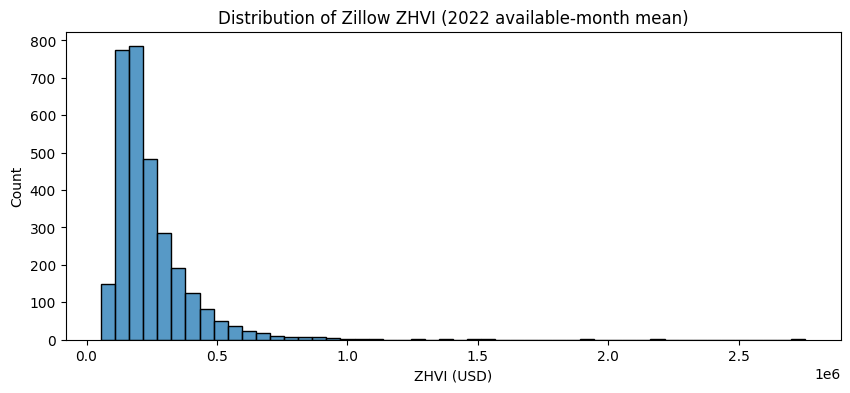

In [7]:
plt.figure(figsize=(10, 4))
sns.histplot(eda_df["zhvi_2022"], bins=50, kde=False)
plt.title("Distribution of Zillow ZHVI (2022 available-month mean)")
plt.xlabel("ZHVI (USD)")
plt.ylabel("Count")
plt.show()


### 4.2 Log transformation of housing prices

To reduce skewness and improve linear interpretability, we define:

$$
\text{log\_zhvi} = \log(\text{zhvi\_2022})
$$

Using log prices:
- Reduces the influence of extreme counties
- Produces a more symmetric, regression-friendly distribution
- Allows coefficients to be interpreted approximately as percentage changes

All subsequent analyses treat `log_zhvi` as the primary outcome.

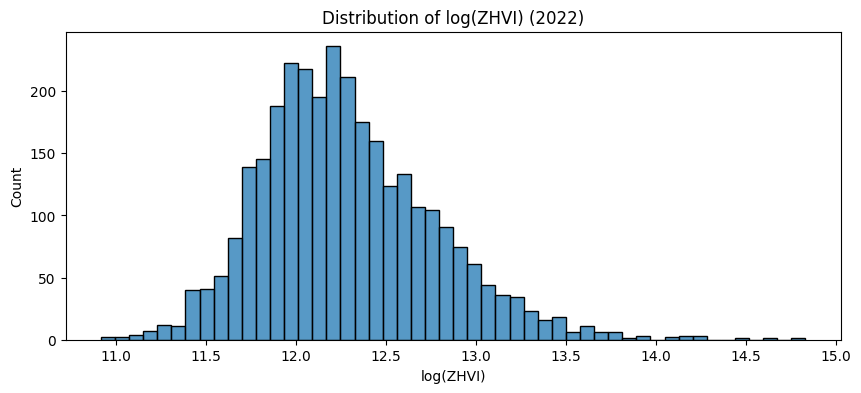

In [8]:
eda_df["log_zhvi"] = np.log(eda_df["zhvi_2022"])

plt.figure(figsize=(10, 4))
sns.histplot(eda_df["log_zhvi"], bins=50, kde=False)
plt.title("Distribution of log(ZHVI) (2022)")
plt.xlabel("log(ZHVI)")
plt.ylabel("Count")
plt.show()


## Step 5. Predictor Distributions and Scale Transformations

We examine the distributions of key predictors to assess skewness and scale heterogeneity.

High-level patterns:
- `median_income_2022`: right-skewed
- `population_2022`: extremely right-skewed (large metropolitan counties)
- `ba_plus_share_2022`: right-skewed
- `hs_plus_share_2022`: left-skewed (most counties already high)
- `avg_household_size_2022`: relatively concentrated
- `unemployment_rate_2022`: right-skewed


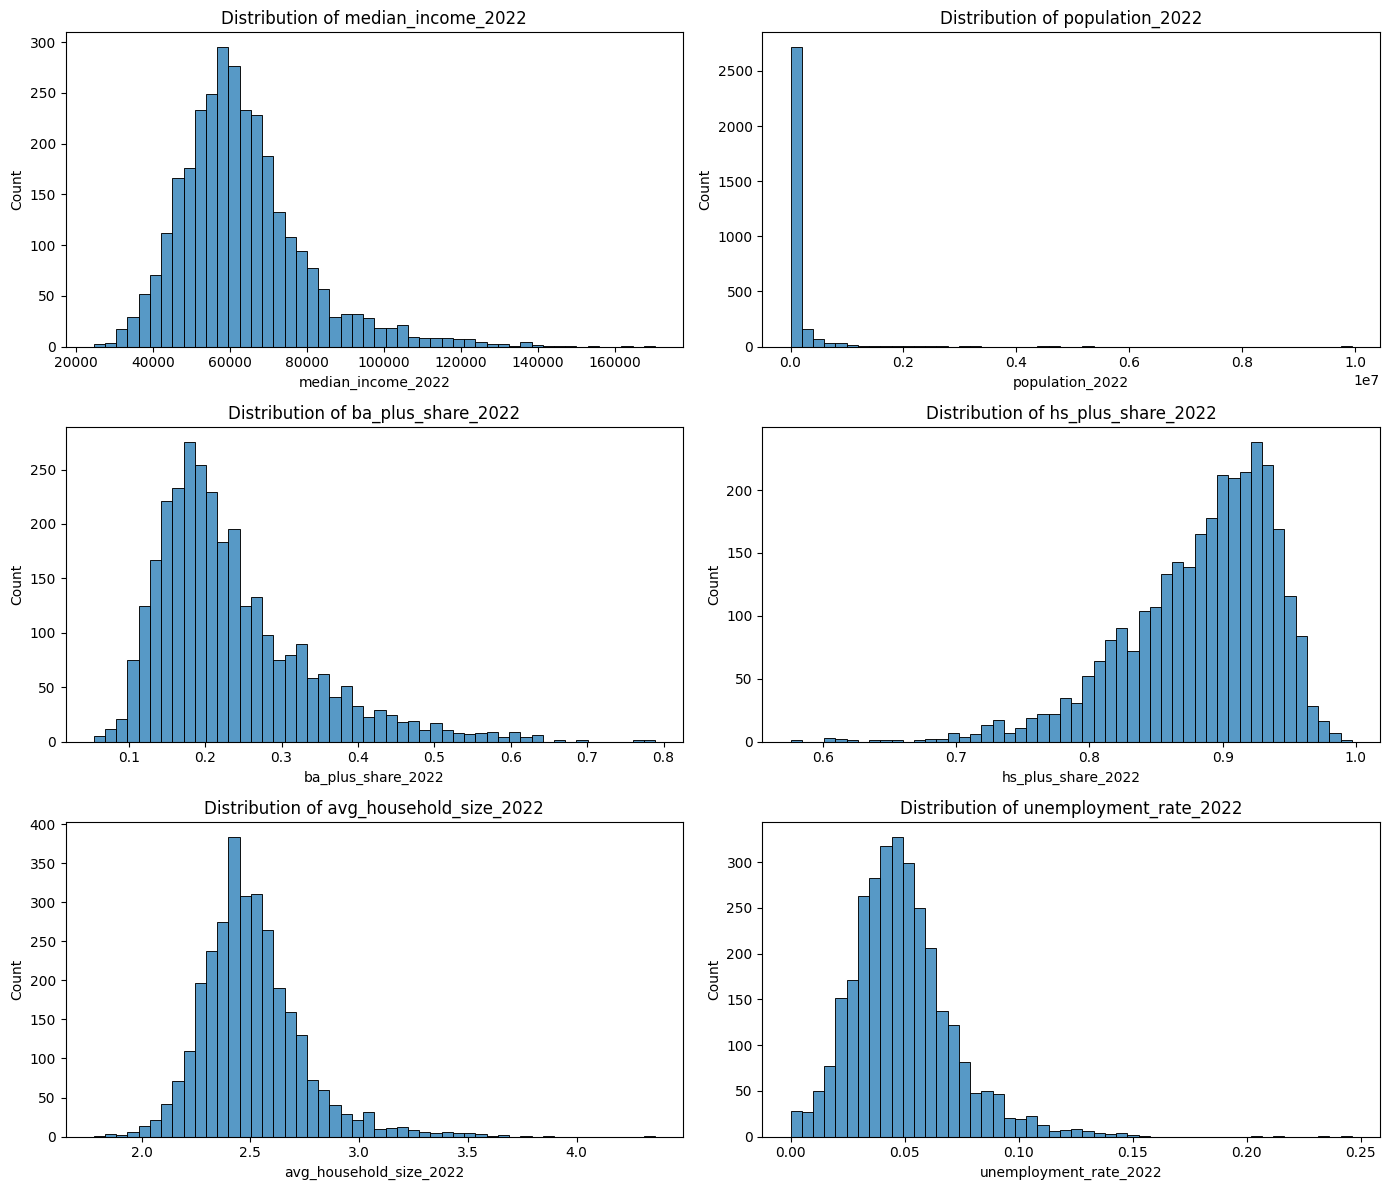

In [9]:
num_cols = [
    "median_income_2022",
    "population_2022",
    "ba_plus_share_2022",
    "hs_plus_share_2022",
    "avg_household_size_2022",
    "unemployment_rate_2022",
]

n_cols = 2
n_rows = int(np.ceil(len(num_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    sns.histplot(eda_df[col], bins=50, kde=False, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")

# Remove empty subplots (if any)
for ax in axes[len(num_cols):]:
    ax.remove()

plt.tight_layout()
plt.show()


### Log-transform scale variables

Population and labor-force counts span multiple orders of magnitude.
To stabilize variance and reduce leverage from very large counties, we construct:

- `log_population = log1p(population_2022)`
- (diagnostic only) `log_labor_force = log1p(civilian_labor_force_2022)`

Design choices:
- Income remains in levels (USD) for interpretability
- Education shares remain proportions (0–1)
- Household size remains in levels
- Unemployment is represented using the rate, not raw counts


In [10]:
eda_df["log_population"] = np.log1p(eda_df["population_2022"])
eda_df["log_labor_force"] = np.log1p(eda_df["civilian_labor_force_2022"])

eda_df[["zhvi_2022", "log_zhvi", "population_2022", "log_population"]].head()


,zhvi_2022,log_zhvi,population_2022,log_population
0,822473.001114,13.620071,9936690,16.111745
1,282612.668412,12.551833,5225367,15.469036
2,279352.397555,12.540229,4726177,15.368627
3,483807.870034,13.089443,4430871,15.304107
4,850809.443854,13.653943,3289701,15.006308


## Step 6. Bivariate Relationships with `log_zhvi`

Before multivariate modeling, we visualize bivariate relationships to assess
direction, strength, and heterogeneity.

Key patterns:
- Median income and BA+ share show the strongest positive associations with `log_zhvi`
- `log_population` is positively related but more heterogeneous
- Average household size shows weak association
- Unemployment rate shows a negative association in isolation, but weaker than income
  and education


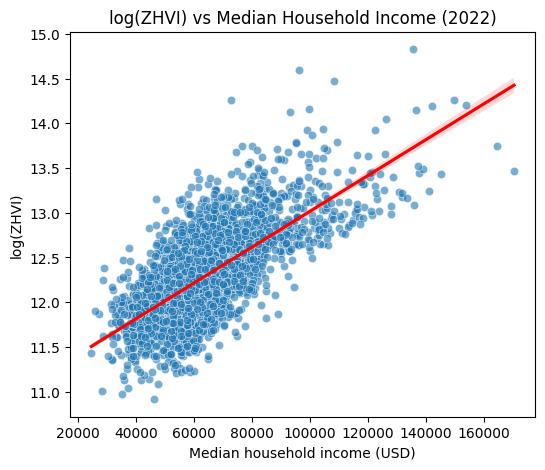

In [11]:
plt.figure(figsize=(6, 5))
sns.scatterplot(
    data=eda_df,
    x="median_income_2022",
    y="log_zhvi",
    alpha=0.6
)
sns.regplot(
    data=eda_df,
    x="median_income_2022",
    y="log_zhvi",
    scatter=False,
    color="red"
)
plt.title("log(ZHVI) vs Median Household Income (2022)")
plt.xlabel("Median household income (USD)")
plt.ylabel("log(ZHVI)")
plt.show()


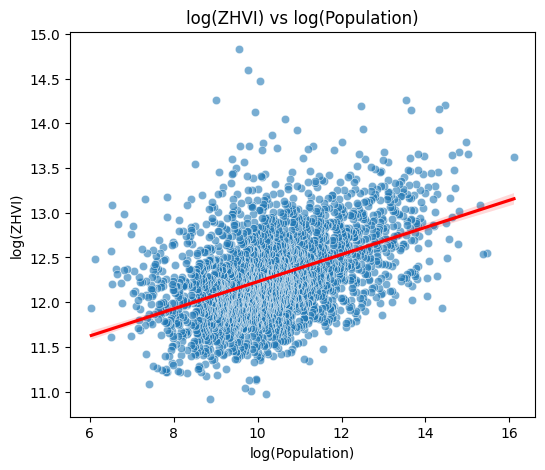

In [12]:
plt.figure(figsize=(6, 5))
sns.scatterplot(
    data=eda_df,
    x="log_population",
    y="log_zhvi",
    alpha=0.6
)
sns.regplot(
    data=eda_df,
    x="log_population",
    y="log_zhvi",
    scatter=False,
    color="red"
)
plt.title("log(ZHVI) vs log(Population)")
plt.xlabel("log(Population)")
plt.ylabel("log(ZHVI)")
plt.show()


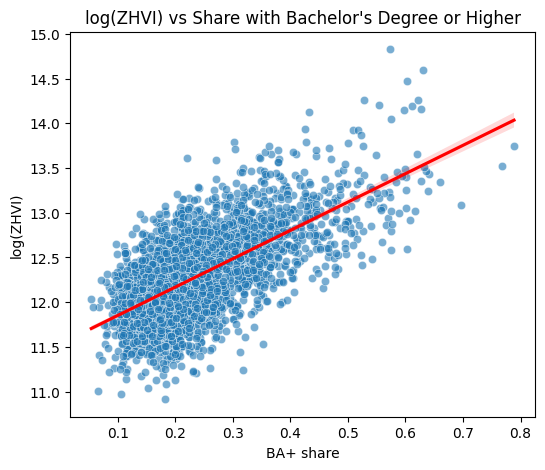

In [13]:
plt.figure(figsize=(6, 5))
sns.scatterplot(
    data=eda_df,
    x="ba_plus_share_2022",
    y="log_zhvi",
    alpha=0.6
)
sns.regplot(
    data=eda_df,
    x="ba_plus_share_2022",
    y="log_zhvi",
    scatter=False,
    color="red"
)
plt.title("log(ZHVI) vs Share with Bachelor's Degree or Higher")
plt.xlabel("BA+ share")
plt.ylabel("log(ZHVI)")
plt.show()


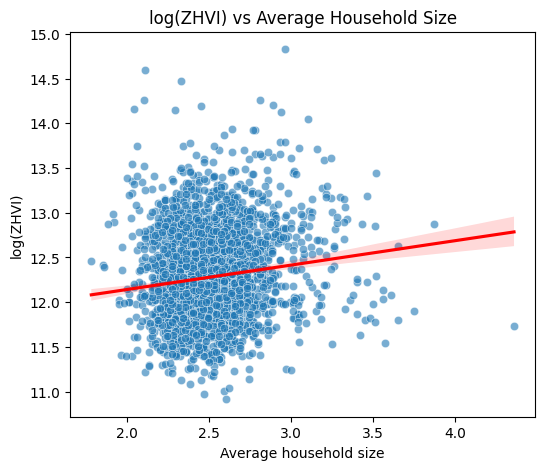

In [14]:
plt.figure(figsize=(6, 5))
sns.scatterplot(
    data=eda_df,
    x="avg_household_size_2022",
    y="log_zhvi",
    alpha=0.6
)
sns.regplot(
    data=eda_df,
    x="avg_household_size_2022",
    y="log_zhvi",
    scatter=False,
    color="red"
)
plt.title("log(ZHVI) vs Average Household Size")
plt.xlabel("Average household size")
plt.ylabel("log(ZHVI)")
plt.show()


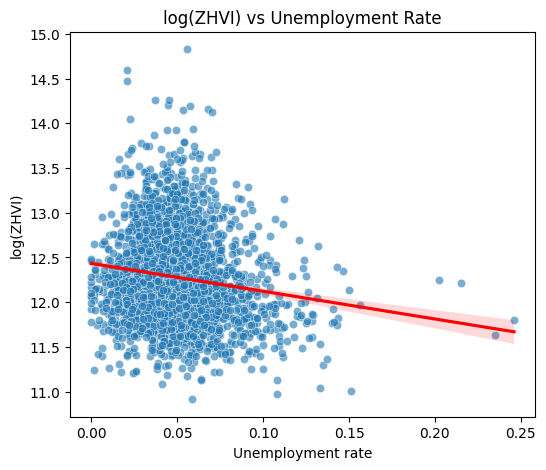

In [15]:
plt.figure(figsize=(6, 5))
sns.scatterplot(
    data=eda_df,
    x="unemployment_rate_2022",
    y="log_zhvi",
    alpha=0.6
)
sns.regplot(
    data=eda_df,
    x="unemployment_rate_2022",
    y="log_zhvi",
    scatter=False,
    color="red"
)
plt.title("log(ZHVI) vs Unemployment Rate")
plt.xlabel("Unemployment rate")
plt.ylabel("log(ZHVI)")
plt.show()


## Step 7. Correlation Structure and Multicollinearity Risk

We examine correlations among predictors to assess multicollinearity.

Key implications:
- Income and BA+ share are strongly correlated, reflecting overlapping socioeconomic
  advantage
- Population is moderately correlated with income and education, capturing urban scale
- HS+ share has weaker correlation with housing prices than BA+
- Unemployment is negatively correlated with income and education

As a result, regression coefficients must be interpreted **conditionally** rather than
as independent causal effects.


In [16]:
corr_vars = [
    "log_zhvi",
    "median_income_2022",
    "ba_plus_share_2022",
    "hs_plus_share_2022",
    "log_population",
    "avg_household_size_2022",
    "unemployment_rate_2022",
]

corr_df = eda_df[corr_vars].copy()
corr_df.head()


,log_zhvi,median_income_2022,ba_plus_share_2022,hs_plus_share_2022,log_population,avg_household_size_2022,unemployment_rate_2022
0,13.620071,83411.0,0.345829,0.802500,16.111745,2.89,0.069825
1,12.551833,78304.0,0.412836,0.882084,15.469036,2.49,0.070836
2,12.540229,70789.0,0.331670,0.821452,15.368627,2.77,0.063886
3,13.089443,80675.0,0.349849,0.891755,15.304107,2.62,0.047556
4,13.653943,96974.0,0.410468,0.887121,15.006308,2.78,0.063408


In [17]:
corr_matrix = corr_df.corr()
corr_matrix


,log_zhvi,median_income_2022,ba_plus_share_2022,hs_plus_share_2022,log_population,avg_household_size_2022,unemployment_rate_2022
log_zhvi,1.000000,0.695443,0.662493,0.336653,0.456952,0.133101,-0.147368
median_income_2022,0.695443,1.000000,0.716305,0.498624,0.426751,0.147234,-0.337661
ba_plus_share_2022,0.662493,0.716305,1.000000,0.586916,0.493509,-0.134791,-0.224445
hs_plus_share_2022,0.336653,0.498624,0.586916,1.000000,0.143190,-0.391294,-0.374628
log_population,0.456952,0.426751,0.493509,0.143190,1.000000,0.141584,0.132625
avg_household_size_2022,0.133101,0.147234,-0.134791,-0.391294,0.141584,1.000000,0.144118
unemployment_rate_2022,-0.147368,-0.337661,-0.224445,-0.374628,0.132625,0.144118,1.000000


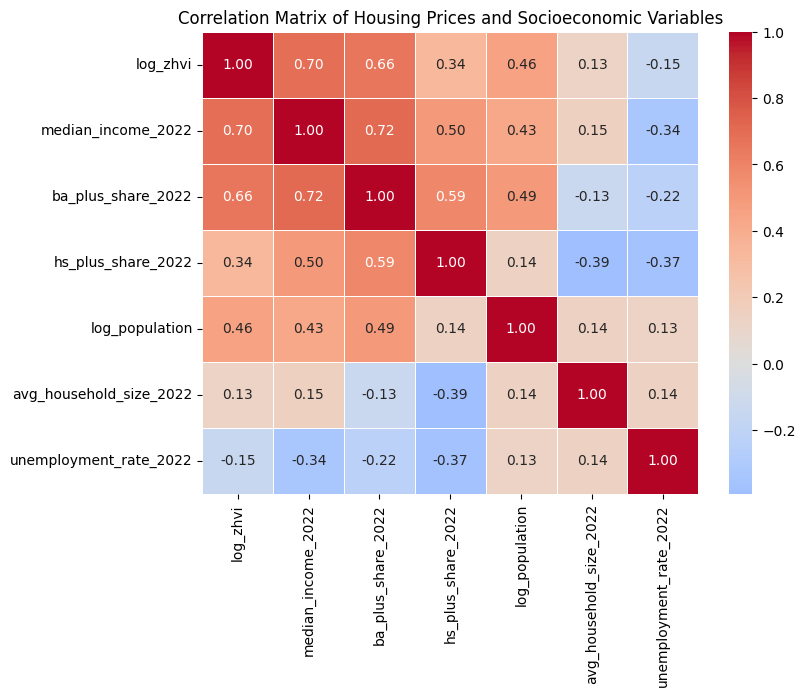

In [18]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)
plt.title("Correlation Matrix of Housing Prices and Socioeconomic Variables")
plt.show()


## Step 8. Stepwise Interpretable Regression

We estimate a sequence of linear models with `log_zhvi` as the dependent variable.
The goal is interpretability: to observe coefficient stability as covariates are added.

Model sequence:
1. Income only  
2. + Education composition (BA+, HS+)  
3. + Urban scale (`log_population`)  
4. + Household structure and labor market conditions  

Because the dependent variable is log-transformed, coefficients can be interpreted
approximately as percentage changes.


In [19]:
import statsmodels.api as sm

# Select variables
reg_vars = [
    "log_zhvi",
    "median_income_2022",
    "ba_plus_share_2022",
    "hs_plus_share_2022",
    "log_population",
    "avg_household_size_2022",
    "unemployment_rate_2022",
]

reg_df = eda_df[reg_vars].dropna().copy()

y = reg_df["log_zhvi"]


### Model 1: Median Income Only (Baseline)


In [20]:
X1 = sm.add_constant(reg_df[["median_income_2022"]])
model1 = sm.OLS(y, X1).fit()
model1.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               log_zhvi   R-squared:                       0.484
Model:                            OLS   Adj. R-squared:                  0.483
Method:                 Least Squares   F-statistic:                     2857.
Date:                Sun, 01 Nov 2026   Prob (F-statistic):               0.00
Time:                        19:21:09   Log-Likelihood:                -1096.8
No. Observations:                3052   AIC:                             2198.
Df Residuals:                    3050   BIC:                             2210.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 11.0113      0.025    448.222      0.000      10.963      11.059
median_income_2022  2.004e-05   3.75e-07     53.448      0.000    1.93e-05    2.08e-05
==============================================================================
Omnibus:                      114.117   Durbin-Watson:                   1.880
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              142.991
Skew:                           0.413   Prob(JB):                     8.91e-32
Kurtosis:                       3.666   Cond. No.                     2.57e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.57e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

### Model 2: Adding Educational Attainment


In [21]:
X2 = sm.add_constant(
    reg_df[["median_income_2022", "ba_plus_share_2022", "hs_plus_share_2022"]]
)
model2 = sm.OLS(y, X2).fit()
model2.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               log_zhvi   R-squared:                       0.551
Model:                            OLS   Adj. R-squared:                  0.551
Method:                 Least Squares   F-statistic:                     1247.
Date:                Sun, 01 Nov 2026   Prob (F-statistic):               0.00
Time:                        19:21:09   Log-Likelihood:                -883.25
No. Observations:                3052   AIC:                             1775.
Df Residuals:                    3048   BIC:                             1799.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 12.0027      0.106    113.375      0.000      11.795      12.210
median_income_2022   1.37e-05   5.06e-07     27.080      0.000    1.27e-05    1.47e-05
ba_plus_share_2022     1.9243      0.090     21.373      0.000       1.748       2.101
hs_plus_share_2022    -1.1804      0.131     -9.008      0.000      -1.437      -0.923
==============================================================================
Omnibus:                       47.617   Durbin-Watson:                   1.922
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               54.551
Skew:                           0.253   Prob(JB):                     1.43e-12
Kurtosis:                       3.416   Cond. No.                     1.93e+06
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.93e+06. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

### Model 3: Adding Population Scale


In [22]:
X3 = sm.add_constant(
    reg_df[
        [
            "median_income_2022",
            "ba_plus_share_2022",
            "hs_plus_share_2022",
            "log_population",
        ]
    ]
)
model3 = sm.OLS(y, X3).fit()
model3.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               log_zhvi   R-squared:                       0.559
Model:                            OLS   Adj. R-squared:                  0.558
Method:                 Least Squares   F-statistic:                     965.8
Date:                Sun, 01 Nov 2026   Prob (F-statistic):               0.00
Time:                        19:21:09   Log-Likelihood:                -855.79
No. Observations:                3052   AIC:                             1722.
Df Residuals:                    3047   BIC:                             1752.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 11.5342      0.122     94.241      0.000      11.294      11.774
median_income_2022  1.312e-05   5.08e-07     25.845      0.000    1.21e-05    1.41e-05
ba_plus_share_2022     1.6685      0.096     17.446      0.000       1.481       1.856
hs_plus_share_2022    -0.9536      0.133     -7.147      0.000      -1.215      -0.692
log_population         0.0353      0.005      7.438      0.000       0.026       0.045
==============================================================================
Omnibus:                       79.195   Durbin-Watson:                   1.956
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               90.916
Skew:                           0.353   Prob(JB):                     1.81e-20
Kurtosis:                       3.466   Cond. No.                     2.09e+06
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.09e+06. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

### Model 4: Full Socioeconomic Controls


In [23]:
X4 = sm.add_constant(
    reg_df[
        [
            "median_income_2022",
            "ba_plus_share_2022",
            "hs_plus_share_2022",
            "log_population",
            "avg_household_size_2022",
            "unemployment_rate_2022",
        ]
    ]
)
model4 = sm.OLS(y, X4).fit()
model4.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               log_zhvi   R-squared:                       0.564
Model:                            OLS   Adj. R-squared:                  0.564
Method:                 Least Squares   F-statistic:                     657.7
Date:                Sun, 01 Nov 2026   Prob (F-statistic):               0.00
Time:                        19:21:09   Log-Likelihood:                -837.09
No. Observations:                3052   AIC:                             1688.
Df Residuals:                    3045   BIC:                             1730.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
===========================================================================================
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                      10.8074      0.171     63.106      0.000      10.472      11.143
median_income_2022       1.216e-05   5.84e-07     20.828      0.000     1.1e-05    1.33e-05
ba_plus_share_2022          1.7764      0.097     18.229      0.000       1.585       1.967
hs_plus_share_2022         -0.5203      0.150     -3.461      0.001      -0.815      -0.226
log_population              0.0288      0.005      5.811      0.000       0.019       0.038
avg_household_size_2022     0.1649      0.030      5.437      0.000       0.105       0.224
unemployment_rate_2022      0.6902      0.293      2.357      0.018       0.116       1.264
==============================================================================
Omnibus:                       75.692   Durbin-Watson:                   1.956
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               87.203
Skew:                           0.341   Prob(JB):                     1.16e-19
Kurtosis:                       3.470   Cond. No.                     3.38e+06
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 3.38e+06. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

### Model Comparison and Multicollinearity Considerations


In [24]:
comparison = pd.DataFrame(
    {
        "Model 1": model1.params,
        "Model 2": model2.params,
        "Model 3": model3.params,
        "Model 4": model4.params,
    }
)

comparison


,Model 1,Model 2,Model 3,Model 4
avg_household_size_2022,NaN,NaN,NaN,0.164893
ba_plus_share_2022,NaN,1.924262,1.668452,1.776410
const,11.011318,12.002680,11.534177,10.807401
hs_plus_share_2022,NaN,-1.180390,-0.953591,-0.520350
log_population,NaN,NaN,0.035337,0.028783
median_income_2022,0.000020,0.000014,0.000013,0.000012
unemployment_rate_2022,NaN,NaN,NaN,0.690167


In [25]:
row_order = [
    "const",
    "median_income_2022",
    "ba_plus_share_2022",
    "hs_plus_share_2022",
    "log_population",
    "avg_household_size_2022",
    "unemployment_rate_2022",
]

comparison_clean = comparison.reindex(row_order)

comparison_fmt = comparison_clean.apply(
    lambda col: col.map(lambda x: "" if pd.isna(x) else f"{x:.6g}")
)

comparison_fmt


,Model 1,Model 2,Model 3,Model 4
const,11.0113,12.0027,11.5342,10.8074
median_income_2022,2.00377e-05,1.37026e-05,1.31199e-05,1.21556e-05
ba_plus_share_2022,,1.92426,1.66845,1.77641
hs_plus_share_2022,,-1.18039,-0.953591,-0.52035
log_population,,,0.0353374,0.0287828
avg_household_size_2022,,,,0.164893
unemployment_rate_2022,,,,0.690167


## EDA Summary and Modeling Implications

- Log home values are used to summarize conditional associations.
- Income and BA+ have the largest positive bivariate correlations among these predictors;
  this is not a ranking of conditional importance or causal effects.
- Population and household size are controls with conditional interpretations.
- HS+ is explored in the sequence here; the final five-predictor model is in notebook 04.
- Unemployment is negatively correlated with log home values in isolation and positive
  in the full specification. This does not identify an economic mechanism.
- Correlation suggests checking collinearity, not assuming it is severe. The final
  model's intercept-aware VIFs in notebook 04 are 1.26–2.67.
- ACS covariates summarize 2018–2022, while Zillow summarizes available months in 2022.
  Inner joins select overlapping counties rather than guaranteeing national coverage.
